# AITR 7: citation-consensus walkthrough
Chinmay Thakur · MDE2026011

Executed against the included raw data. This is decision replay and new consensus post-processing, not live execution of the original checkers. Both dataset versions are retained; corrected-label results are emphasized.

In [1]:
from pathlib import Path
import sys,json,csv
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
assert (ROOT/'configs/protocol.json').exists()
sys.path.insert(0,str(ROOT))
from src.consensus import load_records,metrics,vote,triage,leave_one_document_out,TOOLS
print('Project found; five tools:', ', '.join(TOOLS))

Project found; five tools: checkifexist, hallucitechecker, hallucinator, halref, refchecker


## 1. Validate data and inspect the real label correction

In [2]:
original=load_records(ROOT/'data/raw/manual_reference_verification_dataset.csv')
corrected=load_records(ROOT/'data/corrected/manual_reference_verification_dataset.csv')
for name,rows in [('v1.0.0',original),('v1.1.0',corrected)]:
 print(name, 'rows=',len(rows),'problematic=',sum(r.label for r in rows),'verified=',sum(1-r.label for r in rows))
for a,b in zip(original,corrected):
 assert a.uid==b.uid and a.flags==b.flags
 if a.label!=b.label:print('Corrected:',a.uid,a.label,'->',b.label,'flags=',b.flags)

v1.0.0 rows= 104 problematic= 33 verified= 71
v1.1.0 rows= 104 problematic= 35 verified= 69
Corrected: P3:R12 0 -> 1 flags= (0, 0, 0, 1, 1)
Corrected: P3:R18 0 -> 1 flags= (0, 0, 1, 1, 1)


## 2. Trace the reusable algorithm
Only the five flags enter the predictor. This fixture illustrates the rule; it is not a measured dataset outcome.

In [3]:
flags=(1,1,1,0,0)
print('Flags:',flags,'sum:',sum(flags))
print('k=3:',vote(flags,3),'k=4:',vote(flags,4),'triage:',triage(flags))
try:vote((1,0,1,None,0),3)
except ValueError as e:print('Missing input rejected:',e)

Flags: (1, 1, 1, 0, 0) sum: 3
k=3: 1 k=4: 0 triage: review
Missing input rejected: Flags must be non-empty binary integers


## 3. Reconstruct the published baseline and compute actual corrected results

In [4]:
j=TOOLS.index('refchecker')
old=metrics([r.label for r in original],[r.flags[j] for r in original])
print('Historical RefChecker:',{k:old[k] for k in ['tp','fp','tn','fn']})
assert [old[k] for k in ['tp','fp','tn','fn']]==[32,36,35,1]
y=[r.label for r in corrected]
for name,p in [('RefChecker',[r.flags[j] for r in corrected]),('Majority k3',[vote(r.flags,3) for r in corrected]),('Strict k4',[vote(r.flags,4) for r in corrected])]:
 m=metrics(y,p)
 print(name,{k:round(m[k],6) for k in ['tp','fp','tn','fn','recall','false_positive_rate','balanced_accuracy']})

Historical RefChecker: {'tp': 32, 'fp': 36, 'tn': 35, 'fn': 1}
RefChecker {'tp': 34, 'fp': 34, 'tn': 35, 'fn': 1, 'recall': 0.971429, 'false_positive_rate': 0.492754, 'balanced_accuracy': 0.739337}
Majority k3 {'tp': 31, 'fp': 36, 'tn': 33, 'fn': 4, 'recall': 0.885714, 'false_positive_rate': 0.521739, 'balanced_accuracy': 0.681988}
Strict k4 {'tp': 25, 'fp': 9, 'tn': 60, 'fn': 10, 'recall': 0.714286, 'false_positive_rate': 0.130435, 'balanced_accuracy': 0.791925}


## 4. Hold an entire source document out
Training uses other documents only. The method selects k by their mean document balanced accuracy. These three folds are too few for population generalization claims.

In [5]:
pred,folds=leave_one_document_out(corrected)
for fold in folds:
 print('Test',fold['held_out_document'],'train n=',len(fold['train_ids']),'selected k=',fold['threshold'],'test BA=',round(fold['test_metrics']['balanced_accuracy'],6))
print('Pooled held-out BA:',metrics(y,pred)['balanced_accuracy'])

Test P1 train n= 80 selected k= 4 test BA= 0.571429
Test P2 train n= 89 selected k= 4 test BA= 0.579545
Test P3 train n= 39 selected k= 2 test BA= 0.648649
Pooled held-out BA: 0.7039337474120082


## 5. Recompute the complete corrected experiment
This writes a separate output directory and checks the measured table against the delivered table. Timestamps and microtimings can differ.

In [6]:
import subprocess
run=subprocess.run([sys.executable,str(ROOT/'scripts/run_study.py'),'--corrected','--out','results/notebook_rerun'],cwd=ROOT,text=True,capture_output=True,check=True)
print(run.stdout)
assert (ROOT/'results/notebook_rerun/metrics.csv').read_bytes()==(ROOT/'results/corrected/metrics.csv').read_bytes()
print('Notebook metrics exactly match the delivered corrected results.')

DATA VALIDATED: 104 references; 35 problematic; 69 verified
CORRECTED-LABEL BASELINE: {'tp': 34, 'fp': 34, 'tn': 35, 'fn': 1}
method                 TP FP TN FN   recall   FPR     balanced_accuracy
checkifexist           31 34 35  4   0.886    0.493   0.696
hallucitechecker       18 20 49 17   0.514    0.290   0.612
hallucinator           30 27 42  5   0.857    0.391   0.733
halref                 26 51 18  9   0.743    0.739   0.502
refchecker             34 34 35  1   0.971    0.493   0.739
vote_k1                35 68  1  0   1.000    0.986   0.507
vote_k2                35 52 17  0   1.000    0.754   0.623
vote_k3                31 36 33  4   0.886    0.522   0.682
vote_k4                25  9 60 10   0.714    0.130   0.792
vote_k5                13  1 68 22   0.371    0.014   0.678
lodo_selected          30 31 38  5   0.857    0.449   0.704
PRIMARY SUCCESS RULE: {'fpr_reduction': -0.02898550724637683, 'majority_recall': 0.8857142857142857, 'meets_prespecified_rule': False}
LODO TH

## 6. Read measured figures and the triage denominator

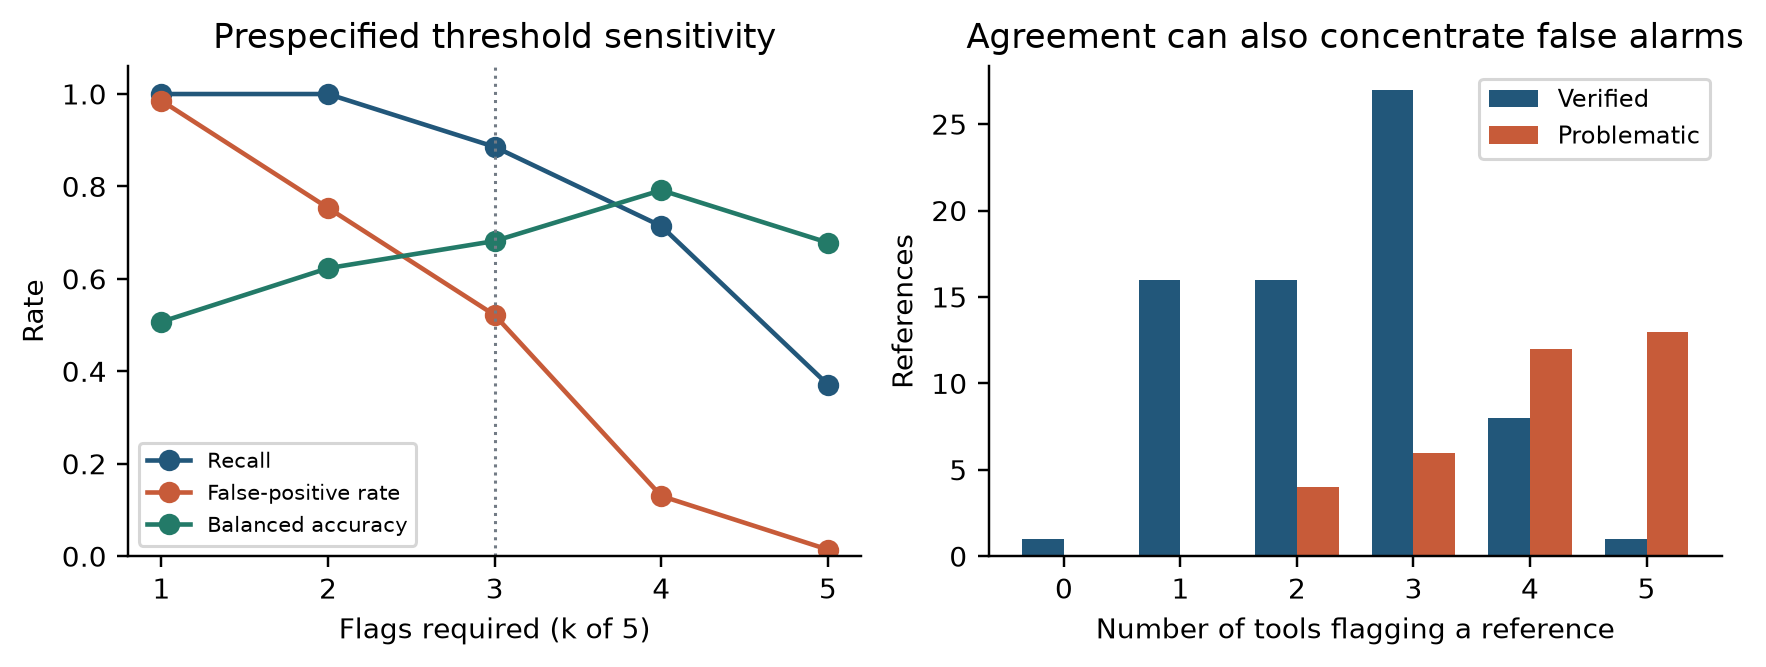

Automatic: 51 Deferred: 53
{'decision': 'auto_accept', 'count': 17, 'verified': 17, 'problematic': 0}
{'decision': 'review', 'count': 53, 'verified': 43, 'problematic': 10}
{'decision': 'auto_flag', 'count': 34, 'verified': 9, 'problematic': 25}
Automatic errors: 9


In [7]:
from IPython.display import display,Image
display(Image(filename=str(ROOT/'results/corrected/figures/02_thresholds_and_votes.png'),width=1000))
t=json.loads((ROOT/'results/corrected/triage.json').read_text())
print('Automatic:',t['automatic_count'],'Deferred:',t['deferred_count'])
for group in t['groups']:print(group)
print('Automatic errors:',t['automatic_metrics']['fp']+t['automatic_metrics']['fn'])

## 7. Interpretation and limits
The primary majority target fails on both versions. Four votes trade away recall; favorable four-tool removals are descriptive, not independently selected panels. Triage defers ten corrected-label problems, so its automatic-subset recall is not overall recall. Ground truth and checker decisions are inherited. No live tool latency, human trust, formatting intervention, or claim support is measured.

See the paper, protocol amendments, AI log and viva guide. Personal understanding and a student-delivered demonstration remain the student's responsibility.